# Logistic regression on the students dataset

The task: predict pass or fail (pass means a final grade above 4) from the lab average. In the anatomy of the course: the model is a sigmoid applied to a linear score, the objective is the log loss, the optimization is gradient based, and the validation uses accuracy on the predictions. This notebook first contrasts a linear fit with the logistic fit, then trains logistic regression by hand with gradient descent.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import r2_score
import matplotlib.gridspec as gridspec
import seaborn as sns


# Create the dataset
data = {
    'Quizzes': [5.3, 5.5, 5.5, 5.0, 2.5, 3.0, 3.0, 3.1, 3.5, 3.5, 3.7, 4.0, 4.0, 4.0, 4.0, 5.7],
    'Labs': [5.3, 5.9, 5.29, 4.35, 5.5, 5.0, 4.0, 3.1, 4.5, 5.62, 5.0, 3.0, 4.0, 5.75, 4.44, 5.9],
    'Final': [4.818, 5.773, 4.464, 5.069, 4.164, 4.091, 3.727, 3.909, 3.518, 4.897, 5.209, 3.0, 3.091, 5.818, 4.069, 5.77]
}

# Convert to DataFrame
df = pd.DataFrame(data)

# Augmenting data by replicating and adding noise
np.random.seed(42)
augmented = []
for i in range(len(df)):
    row = df.iloc[i]
    for _ in range(10):  # Create 10 variations of each record
        noise = np.random.normal(0, 0.2, 3)  # Add Gaussian noise with mean=0 and std=0.2
        new_row = row + noise
        # Ensure values are within boundaries (grades must be between 2 and 6)
        new_row = new_row.clip(2, 6)
        augmented.append(new_row)

# Create augmented DataFrame
df_aug = pd.DataFrame(augmented, columns=df.columns)

# categorical target
# Above 4.0 = "Pass" (1), Below or equal to 4.0 = "Fail" (0)
df_aug['Pass'] = (df_aug['Final'] > 4).astype(int)

# data preparation
X = df_aug[['Labs']]
y = df_aug['Final']
y_class = df_aug['Pass']

## Data exploration

The grade distributions and the pass threshold at 4.

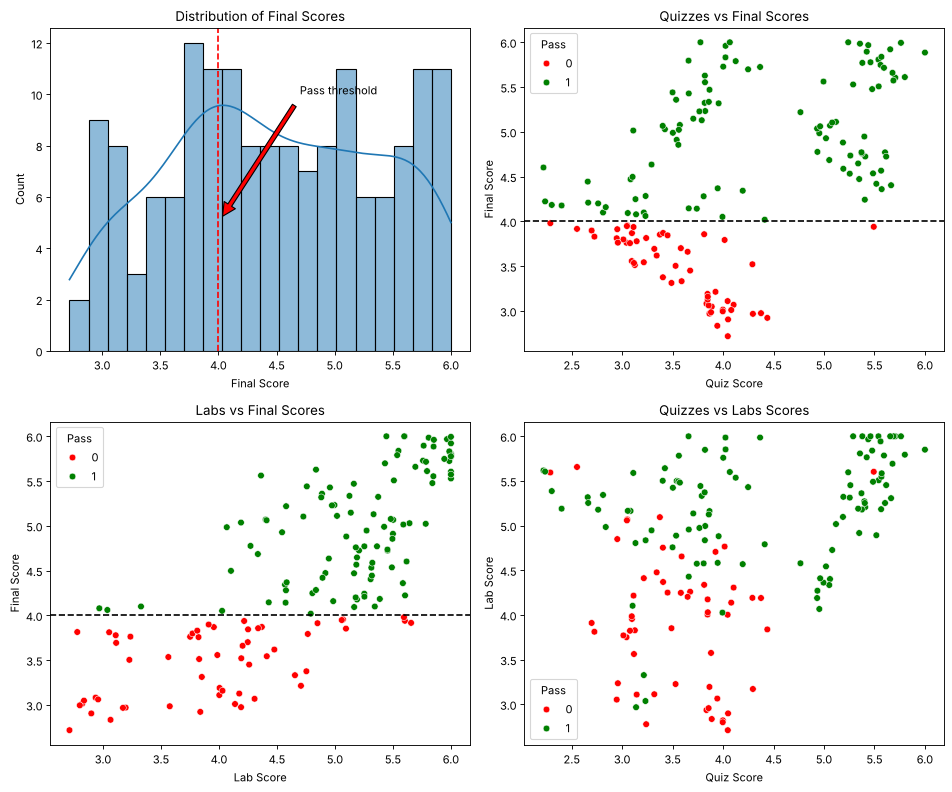

In [2]:
plt.figure(figsize=(12, 10))

# Plot 1: Distribution of Final scores
plt.subplot(2, 2, 1)
sns.histplot(df_aug['Final'], bins=20, kde=True)
plt.axvline(x=4, color='red', linestyle='--')
plt.title('Distribution of Final Scores')
plt.xlabel('Final Score')
plt.ylabel('Count')
plt.annotate('Pass threshold', xy=(4, 5), xytext=(4.7, 10), 
             arrowprops=dict(facecolor='red', shrink=0.05))
# Plot 2: Scatter plot of Quizzes vs Final with Pass/Fail coloring
plt.subplot(2, 2, 2)
sns.scatterplot(data=df_aug, x='Quizzes', y='Final', hue='Pass', palette=['red', 'green'])
plt.axhline(y=4, color='black', linestyle='--')
plt.title('Quizzes vs Final Scores')
plt.xlabel('Quiz Score')
plt.ylabel('Final Score')
# Plot 3: Scatter plot of Labs vs Final with Pass/Fail coloring
plt.subplot(2, 2, 3)
sns.scatterplot(data=df_aug, x='Labs', y='Final', hue='Pass', palette=['red', 'green'])
plt.axhline(y=4, color='black', linestyle='--')
plt.title('Labs vs Final Scores')
plt.xlabel('Lab Score')
plt.ylabel('Final Score')
# Plot 4: Scatter plot of Quizzes vs Labs with Pass/Fail coloring
plt.subplot(2, 2, 4)
sns.scatterplot(data=df_aug, x='Quizzes', y='Labs', hue='Pass', palette=['red', 'green'])
plt.title('Quizzes vs Labs Scores')
plt.xlabel('Quiz Score')
plt.ylabel('Lab Score')

plt.tight_layout()
plt.savefig('data_distribution.png')
plt.show()

## A linear model, then a threshold

We fit plain linear regression to the final grade and call a student a pass when the predicted grade lies above the threshold of 4 (panel 2 of the next figure). The fit shows why classification asks for a different model: the line takes values across the whole real axis, and it returns a grade, while the question is pass or fail and how likely each outcome is. The sigmoid in the next cell keeps every prediction inside $(0, 1)$, so it can be read as the probability of passing.


In [3]:
# Fit linear regression model (only using Labs as feature)
linear_model = LinearRegression()
linear_model.fit(X, y)
linear_pred = linear_model.predict(X)

# smoothing data
X_smooth = pd.DataFrame({'Labs': np.linspace(2, 6, 100)})  # same column name as X
linear_pred_smooth = linear_model.predict(X_smooth)

## The logistic fit

Logistic regression on the same data: the predicted probability follows the sigmoid curve, and the decision boundary sits where the probability crosses 0.5.

Note: scikit-learn's `LogisticRegression` is regularized by default. Its parameter `C` is $1/\lambda$, and the default `C=1.0` adds the ridge penalty from the lecture (frame "Regularized Logistic Regression"). The coefficients printed below, $z = -8.819 + 2.034 \cdot \text{Labs}$, are the ones used in the lecture question "Reading a Trained Model".


Linear Regression: Final = 0.754 + 0.782 × Labs
Linear Model R²: 0.593
Logistic Regression: logit(P(Pass)) = -8.819 + 2.034 × Labs


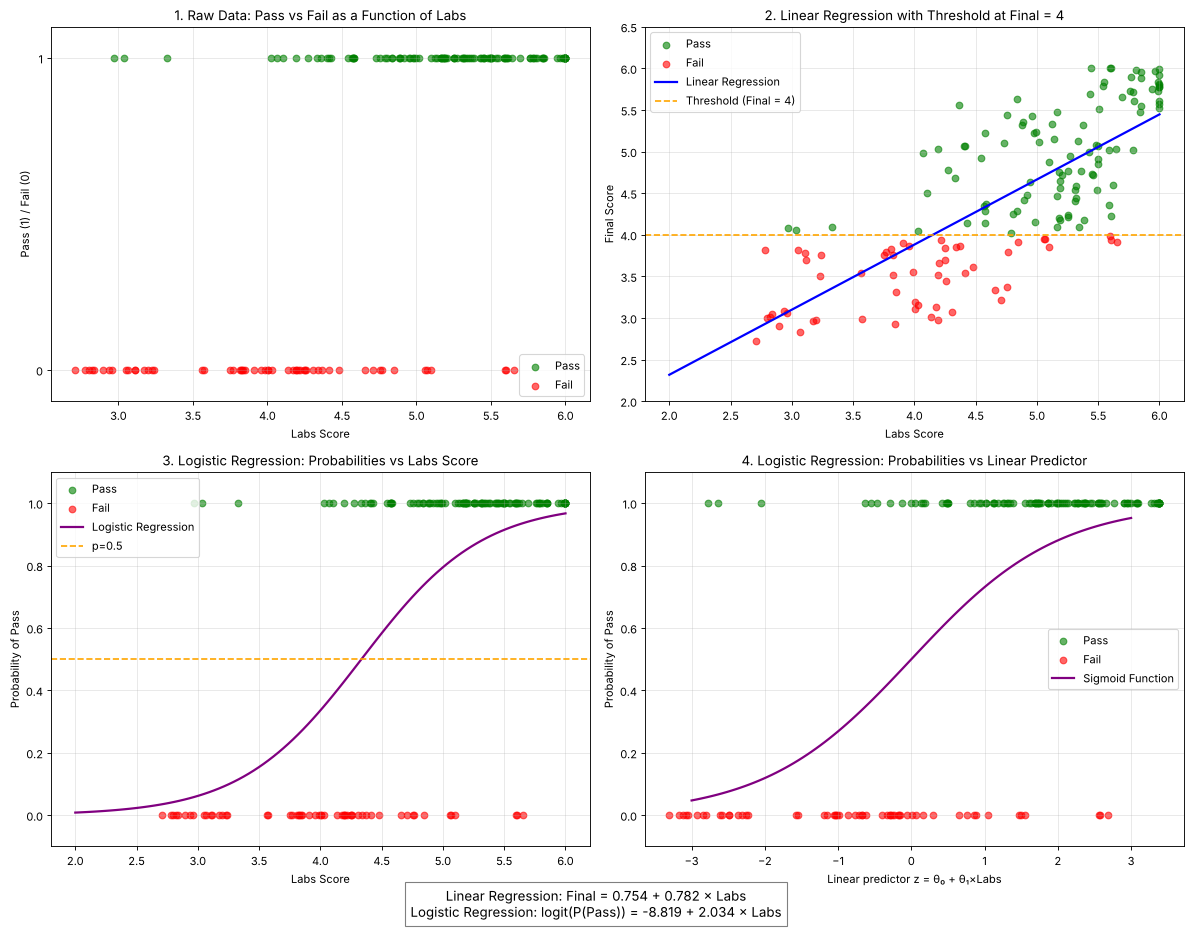

In [4]:
# Fit logistic regression model
logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X, y_class)
logistic_pred_prob = logistic_model.predict_proba(X)[:, 1]  # Probability of pass

# Generate smooth curve for logistic regression
logistic_pred_prob_smooth = logistic_model.predict_proba(X_smooth)[:, 1]

# Calculate the linear predictor (z=theta_0+theta_1*x) for both raw and smooth data
linear_predictor = logistic_model.decision_function(X)
linear_predictor_smooth = logistic_model.decision_function(X_smooth)


plt.figure(figsize=(15, 12))
gs = gridspec.GridSpec(2, 2)

# 1) Raw data of pass vs fail as a function of Labs
ax1 = plt.subplot(gs[0, 0])
ax1.scatter(df_aug.loc[df_aug['Pass'] == 1, 'Labs'], 
           df_aug.loc[df_aug['Pass'] == 1, 'Pass'], 
           c='green', label='Pass', alpha=0.6)
ax1.scatter(df_aug.loc[df_aug['Pass'] == 0, 'Labs'], 
           df_aug.loc[df_aug['Pass'] == 0, 'Pass'], 
           c='red', label='Fail', alpha=0.6)
ax1.set_xlabel('Labs Score')
ax1.set_ylabel('Pass (1) / Fail (0)')
ax1.set_title('1. Raw Data: Pass vs Fail as a Function of Labs')
ax1.grid(True, alpha=0.3)
ax1.legend()
ax1.set_ylim(-0.1, 1.1)
ax1.set_yticks([0, 1])

# 2) Linear regression with a threshold at 4
ax2 = plt.subplot(gs[0, 1])
ax2.scatter(df_aug.loc[df_aug['Pass'] == 1, 'Labs'], 
           df_aug.loc[df_aug['Pass'] == 1, 'Final'], 
           c='green', label='Pass', alpha=0.6)
ax2.scatter(df_aug.loc[df_aug['Pass'] == 0, 'Labs'], 
           df_aug.loc[df_aug['Pass'] == 0, 'Final'], 
           c='red', label='Fail', alpha=0.6)
ax2.plot(X_smooth, linear_pred_smooth, 'b-', linewidth=2, label='Linear Regression')
ax2.axhline(y=4, color='orange', linestyle='--', label='Threshold (Final = 4)')


ax2.set_xlabel('Labs Score')
ax2.set_ylabel('Final Score')


ax2.set_title('2. Linear Regression with Threshold at Final = 4')
ax2.grid(True, alpha=0.3)
ax2.legend()
ax2.set_ylim(2, 6.5)

# 3. Logistic regression showing probabilities as a function of Labs
ax3 = plt.subplot(gs[1, 0])
# Plot pass/fail points at their actual 0/1 values
ax3.scatter(df_aug.loc[df_aug['Pass'] == 1, 'Labs'], 
           np.ones(len(df_aug.loc[df_aug['Pass'] == 1])),
           c='green', label='Pass', alpha=0.6)
ax3.scatter(df_aug.loc[df_aug['Pass'] == 0, 'Labs'], 
           np.zeros(len(df_aug.loc[df_aug['Pass'] == 0])),
           c='red', label='Fail', alpha=0.6)
# Plotting the logistic regression curve
ax3.plot(X_smooth, logistic_pred_prob_smooth, 'purple', linewidth=2, label='Logistic Regression')
ax3.axhline(y=0.5, color='orange', linestyle='--', label='p=0.5')
ax3.set_xlabel('Labs Score')
ax3.set_ylabel('Probability of Pass')
ax3.set_title('3. Logistic Regression: Probabilities vs Labs Score')
ax3.grid(True, alpha=0.3)
ax3.legend()
ax3.set_ylim(-0.1, 1.1)

# 4. Logistic regression showing probabilities as a function of linear predictor
ax4 = plt.subplot(gs[1, 1])
# Plot points colored by their actual pass/fail status
ax4.scatter(linear_predictor[y_class == 1], 
           np.ones(sum(y_class == 1)),
           c='green', label='Pass', alpha=0.6)
ax4.scatter(linear_predictor[y_class == 0], 
           np.zeros(sum(y_class == 0)),
           c='red', label='Fail', alpha=0.6)
# Plotting the sigmoid function
sigmoid = lambda x: 1 / (1 + np.exp(-x))
x_range = np.linspace(-3, 3, 100)
ax4.plot(x_range, sigmoid(x_range), 'purple', linewidth=2, label='Sigmoid Function')
ax4.set_xlabel('Linear predictor z = θ₀ + θ₁×Labs')
ax4.set_ylabel('Probability of Pass')
ax4.set_title('4. Logistic Regression: Probabilities vs Linear Predictor')
ax4.grid(True, alpha=0.3)
ax4.legend()
ax4.set_ylim(-0.1, 1.1)

# model information
plt.figtext(0.5, 0.01, 
           f"Linear Regression: Final = {linear_model.intercept_:.3f} + {linear_model.coef_[0]:.3f} × Labs\n"
           f"Logistic Regression: logit(P(Pass)) = {logistic_model.intercept_[0]:.3f} + {logistic_model.coef_[0][0]:.3f} × Labs",
           ha="center", fontsize=12, bbox={"facecolor":"white", "alpha":0.5, "pad":5})

plt.tight_layout(rect=[0, 0.03, 1, 0.97])
#plt.suptitle('Labs Scores vs Final Exam Outcomes: Linear and Logistic Regression', fontsize=16)
plt.show()

# Print model coefficients
print(f"Linear Regression: Final = {linear_model.intercept_:.3f} + {linear_model.coef_[0]:.3f} × Labs")
print(f"Linear Model R²: {r2_score(y, linear_pred):.3f}")
print(f"Logistic Regression: logit(P(Pass)) = {logistic_model.intercept_[0]:.3f} + {logistic_model.coef_[0][0]:.3f} × Labs")

# Gradient descent training

The class below implements the three pieces from the lecture:

* hypothesis: $\hat{y} = \sigma(\boldsymbol{\theta}^T\mathbf{x})$, with a column of ones for $\theta_0$
* cost: the log loss $J(\boldsymbol{\theta}) = -\frac{1}{M}\sum_m \bigl[y^{(m)}\log\hat{y}^{(m)} + (1-y^{(m)})\log(1-\hat{y}^{(m)})\bigr]$, which is $-\frac{1}{M}\log L(\boldsymbol{\theta})$
* update: $\theta_j \leftarrow \theta_j - \alpha\frac{1}{M}\sum_m(\hat{y}^{(m)} - y^{(m)})\,x_j^{(m)}$, the same formula as for linear regression

`predict` applies the threshold $\tau$: pass when $\hat{y} > \tau$, as in the lecture. This version has no regularization ($\lambda = 0$).


theta after 2000 iterations: [-0.29 35.   33.22]
final cost: 0.0082


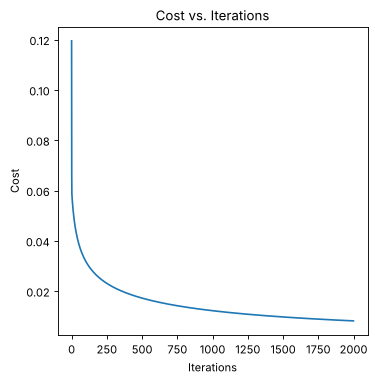

In [5]:


class LogisticRegressionGradientDescent:
    def __init__(self, learning_rate=0.01, num_iterations=1000):
        self.learning_rate = learning_rate
        self.num_iterations = num_iterations
        self.theta = None
        self.cost_history = []
    
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))
    
    def compute_cost(self, X, y, theta):
        M = len(y)
        h = self.sigmoid(np.dot(X, theta))
        
        # Avoid log(0) with small epsilon
        epsilon = 1e-15
        h = np.clip(h, epsilon, 1 - epsilon)
        
        # Compute cost
        cost = -1/M * np.sum(y * np.log(h) + (1 - y) * np.log(1 - h))
        return cost
    
    def gradient_descent(self, X, y):
        M, n = X.shape
        theta = np.zeros(n)
        
        for _ in range(self.num_iterations):
            # Compute hypothesis
            h = self.sigmoid(np.dot(X, theta))
            
            # Compute gradient
            gradient = 1/M * np.dot(X.T, (h - y))
            
            # Update parameters
            theta -= self.learning_rate * gradient
            
            # Track cost
            cost = self.compute_cost(X, y, theta)
            self.cost_history.append(cost)
        
        return theta
    
    def fit(self, X, y):
        # Add intercept term
        X_with_intercept = np.column_stack((np.ones(X.shape[0]), X))
        
        # Run gradient descent
        self.theta = self.gradient_descent(X_with_intercept, y)
        return self
    
    def predict_proba(self, X):
        # Add intercept term
        X_with_intercept = np.column_stack((np.ones(X.shape[0]), X))
        return self.sigmoid(np.dot(X_with_intercept, self.theta))
    
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) > threshold).astype(int)  # pass when y_hat > tau

# Demonstration
def gradient_descent_demo():
    # Generate synthetic data
    np.random.seed(42)
    X = np.random.randn(100, 2)
    y = (X[:, 0] + X[:, 1] > 0).astype(int)
    
    # Create and train model
    model = LogisticRegressionGradientDescent(
        learning_rate=25.8, # note the large number!
        num_iterations=2000
    )
    model.fit(X, y)
    
    # Visualize cost convergence
    plt.figure(figsize=(5, 5))
    plt.plot(model.cost_history)
    plt.title('Cost vs. Iterations')
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    plt.show()
    
    return model

# Run the demonstration
model = gradient_descent_demo()
print('theta after 2000 iterations:', np.round(model.theta, 2))
print('final cost:', round(model.cost_history[-1], 4))

The demonstration uses synthetic data where the line $x_1 + x_2 = 0$ separates the two classes without a single error. On **separable** data the log loss has no finite minimum: the cost keeps falling toward 0 while $\theta_1, \theta_2$ keep growing, and the sigmoid turns into a step (lecture appendix: "When Does the Sigmoid Become a Step Function?"). That is why the large learning rate 25.8 still gives a falling cost here. On the students data below, a learning rate that large would fail.


## Gradient descent on the students data

Now the same class on the lecture example: pass or fail from the lab score. We compare three learning rates over 20000 iterations, the hyperparameter $\alpha$ from L04.


α = 0.01  θ = [-5.53   1.338]   final cost J = 0.4234
α = 0.1   θ = [-9.816  2.252]   final cost J = 0.3944
α = 1.0   θ = [-13.591   3.498]   final cost J = 0.5697


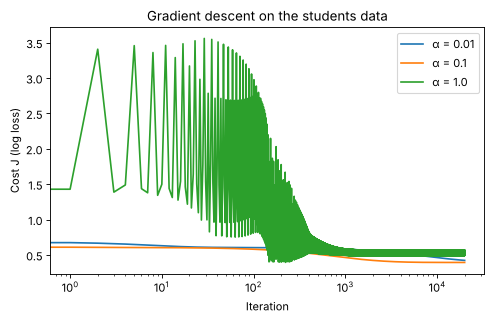

In [6]:
X_labs = df_aug[['Labs']].values
y_pass = df_aug['Pass'].values

plt.figure(figsize=(7, 4))
models = {}
for lr in [0.01, 0.1, 1.0]:
    gd = LogisticRegressionGradientDescent(learning_rate=lr, num_iterations=20000)
    gd.fit(X_labs, y_pass)
    models[lr] = gd
    plt.plot(gd.cost_history, label=f'α = {lr}')
    print(f'α = {lr:<5} θ = {np.round(gd.theta, 3)}   final cost J = {gd.cost_history[-1]:.4f}')
plt.xscale('log')
plt.xlabel('Iteration')
plt.ylabel('Cost J (log loss)')
plt.title('Gradient descent on the students data')
plt.legend()
plt.show()


* $\alpha = 0.01$: the cost falls, but too slowly; after 20000 iterations $\boldsymbol{\theta}$ is still far from the minimum.
* $\alpha = 0.1$: converges to the minimum of the log loss.
* $\alpha = 1.0$: the steps overshoot and the cost stays higher; this is the "too large" learning rate from L04.

The converged $\boldsymbol{\theta}$ is the **maximum likelihood** estimate: the parameters under which the observed pass/fail labels are most probable. The next cell compares it with scikit-learn, with and without regularization, and turns the log loss back into the likelihood.


In [7]:
theta_gd = models[0.1].theta
J_gd = models[0.1].cost_history[-1]
M = len(y_pass)

sk_reg = LogisticRegression().fit(X_labs, y_pass)                       # C = 1, i.e. lambda = 1
sk_noreg = LogisticRegression(C=1e8, max_iter=10000).fit(X_labs, y_pass)  # practically no penalty

print(f'gradient descent (lambda = 0): θ = ({theta_gd[0]:.3f}, {theta_gd[1]:.3f})')
print(f'scikit-learn, C = 1e8:         θ = ({sk_noreg.intercept_[0]:.3f}, {sk_noreg.coef_[0][0]:.3f})')
print(f'scikit-learn, C = 1 (default): θ = ({sk_reg.intercept_[0]:.3f}, {sk_reg.coef_[0][0]:.3f})')
print()
print(f'log loss J = {J_gd:.4f}  ->  likelihood L = exp(-M * J) = {np.exp(-M * J_gd):.2e}  (M = {M})')


gradient descent (lambda = 0): θ = (-9.816, 2.252)
scikit-learn, C = 1e8:         θ = (-9.869, 2.263)
scikit-learn, C = 1 (default): θ = (-8.819, 2.034)

log loss J = 0.3944  ->  likelihood L = exp(-M * J) = 3.94e-28  (M = 160)


Gradient descent without a penalty and scikit-learn with a negligible penalty agree to about two digits (gradient descent stops a few steps short of the exact minimum; the cost $J$ is the same to four decimals). The default `C = 1` shrinks both parameters toward zero: a flatter sigmoid, the effect of $\lambda$ described in the lecture.

The likelihood itself is a tiny number, because it multiplies 160 probabilities. This is why we work with its logarithm.

## Validation: accuracy on held-out students

So far every model was trained and judged on the same 160 students. As in the lecture frame "Training and Validation Data", we keep 30% aside, train on the other 70%, and measure the accuracy on both parts. We repeat this for several values of the regularization hyperparameter `C` $= 1/\lambda$.


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X_labs, y_pass, test_size=0.3, random_state=42)
print(f'{len(y_train)} training students, {len(y_val)} validation students\n')

print(f"{'C':>8} {'lambda':>8} {'theta_0':>9} {'theta_1':>9} {'train acc':>10} {'val acc':>8}")
for C_value in [0.01, 0.1, 1, 10, 1e6]:
    clf = LogisticRegression(C=C_value).fit(X_train, y_train)
    print(f'{C_value:>8g} {1/C_value:>8g} {clf.intercept_[0]:>9.3f} {clf.coef_[0][0]:>9.3f} '
          f'{clf.score(X_train, y_train):>10.3f} {clf.score(X_val, y_val):>8.3f}')


112 training students, 48 validation students

       C   lambda   theta_0   theta_1  train acc  val acc
    0.01      100    -0.845     0.282      0.670    0.750
     0.1       10    -4.737     1.124      0.830    0.833
       1        1    -8.526     1.949      0.866    0.833
      10      0.1    -9.682     2.200      0.866    0.833
   1e+06    1e-06    -9.828     2.232      0.857    0.833


Strong regularization (`C = 0.01`, $\lambda = 100$) pushes $\theta_1$ close to zero: the model barely uses the lab score and underfits, with low training and validation accuracy. From `C = 1` on, the validation accuracy no longer changes. With 48 validation students, accuracy moves in steps of $1/48 \approx 0.02$, so small differences between settings are noise of the split.

### The threshold $\tau$

The threshold is chosen after training. Here the model with `C = 1`, evaluated on the validation students:


In [9]:
clf = LogisticRegression(C=1).fit(X_train, y_train)
p_val = clf.predict_proba(X_val)[:, 1]

for tau in [0.3, 0.5, 0.7]:
    pred = (p_val > tau).astype(int)
    print(f'tau = {tau}:  validation accuracy = {np.mean(pred == y_val):.3f},  '
          f'students predicted to fail = {np.sum(pred == 0)} of {len(y_val)}')


tau = 0.3:  validation accuracy = 0.833,  students predicted to fail = 5 of 48
tau = 0.5:  validation accuracy = 0.833,  students predicted to fail = 13 of 48
tau = 0.7:  validation accuracy = 0.750,  students predicted to fail = 19 of 48


A higher $\tau$ flags more students as at risk of failing. Accuracy alone does not say whether that is better: it depends on which mistake costs more, missing a failing student or a false alarm. The next lecture introduces the metrics that separate the two kinds of mistakes.
